# 04 - From signal to portfolio: the long-short backtest

Notebook 02 asked *"does the score correlate with the next return?"* (IC and accuracy). This notebook asks the question a
trader would ask: **"if I traded on the score, would I make money after costs?"**

| Step | What it answers |
|---|---|
| 1. Load | Same data and the same scores as notebook 02 |
| 2. Ticker-day signal | One row per stock per day, so busy tickers do not count several times |
| 3. Method and maths | How the portfolio is built, what the costs are, how it is judged |
| 4. Check the machinery | Does the backtest find a signal when one exists, and nothing when none does? |
| 5. Results | Test period (all signals comparable) and full sample (untrained signals only) |
| 6. Cost sensitivity | How cheap would trading have to be for the signal to pay? |

It is run on the baseline signals now. The LLM signal is added automatically once its scores exist (section 5).

In [1]:
import sys; sys.path.append('..')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from src.evaluate import ticker_day_signal, long_short_daily, net_of_costs, performance

SEED = 42
np.random.seed(SEED)
PROCESSED = Path('../data/processed')
pd.set_option('display.width', 220)

Q = 5               # quintiles: long the top 20%, short the bottom 20%
MIN_NAMES = 10      # skip a day with fewer than 10 stocks (a quintile would hold fewer than 2)
COST_BPS = 10       # assumed cost per trade, in basis points (1 bp = 0.01%); see the sensitivity table in section 6

## 1. Load the data and the scores

In [2]:
ds = pd.read_csv(PROCESSED / 'dataset.csv', parse_dates=['entry_date'])
ds['row_id'] = ds.index
bs = pd.read_csv(PROCESSED / 'baseline_scores.csv')
assert len(bs) == len(ds) and (bs['row_id'].values == ds['row_id'].values).all(), 'score file does not line up with the dataset'
ds = ds.merge(bs, on='row_id', how='left')
test = ds[ds['split'] == 'test']
print('all rows:', len(ds), '| test rows:', len(test), '| test days:', test['entry_date'].nunique())
print('scores present on test rows:', {c: int(test[c].notna().sum()) for c in ['lexicon', 'finbert', 'tfidf_lr']})

all rows: 30000 | test rows: 7542 | test days: 107
scores present on test rows: {'lexicon': 7542, 'finbert': 7542, 'tfidf_lr': 7542}


## 2. One signal per stock per day

Several headlines can hit the same stock on the same entry day, and they all share **one** target (the same abnormal
return). If every headline were ranked on its own, a busy stock would enter the portfolio several times. So we average the
scores of a stock's headlines for that day. With $H_{i,d}$ the set of headlines for stock $i$ on entry day $d$:

$$
s_{i,d} \;=\; \frac{1}{|H_{i,d}|}\sum_{h \in H_{i,d}} s_h .
$$

In [3]:
# the target must be identical for every headline of a stock-day, otherwise averaging scores would be meaningless
spread = ds.groupby(['ticker', 'entry_date'])['abn_ret'].nunique()
assert (spread == 1).all(), 'abn_ret differs within a ticker-day'
print('every ticker-day has exactly one target value: OK')

td_all = ticker_day_signal(ds, 'finbert')
print(f'headlines: {len(ds):,} -> ticker-days: {len(td_all):,}  ({len(ds) / len(td_all):.2f} headlines per ticker-day)')

# the same return can appear under two entry dates when a holiday rolls forward; how common is it?
dup = td_all.duplicated(['ticker', 'abn_ret'], keep=False).mean()
print(f'ticker-days whose target equals another entry day of the same ticker: {dup:.2%}')

per_day = td_all.groupby('entry_date').size()
print(f'names per day (all rows): median {per_day.median():.0f}, share of days with >= {MIN_NAMES}: {(per_day >= MIN_NAMES).mean():.1%}')
per_day_t = ticker_day_signal(test, 'finbert').groupby('entry_date').size()
print(f'names per day (test rows): median {per_day_t.median():.0f}, share of days with >= {MIN_NAMES}: {(per_day_t >= MIN_NAMES).mean():.1%}')

every ticker-day has exactly one target value: OK
headlines: 30,000 -> ticker-days: 18,126  (1.66 headlines per ticker-day)
ticker-days whose target equals another entry day of the same ticker: 0.49%
names per day (all rows): median 28, share of days with >= 10: 96.7%
names per day (test rows): median 39, share of days with >= 10: 97.2%


## 3. Method and maths

**Portfolio.** On each entry day $d$ with $n_d$ stocks, rank them by signal and let $R_{i,d}\in(0,1]$ be the rank divided by
$n_d$ (tied scores share an average rank). With $q=5$ quintiles:

$$
L_d = \{\, i : R_{i,d} > 1-\tfrac1q \,\}\ \text{(long, top 20\%)}, \qquad
S_d = \{\, i : R_{i,d} \le \tfrac1q \,\}\ \text{(short, bottom 20\%)}.
$$

Stocks in the middle are not traded. A block of exactly tied scores (for the lexicon, most headlines score 0) sits in the
middle by construction, so it is never traded. Positions are equal weighted and held from the entry close to the next close,
the same window as the target.

**Gross daily return** (per \$1 long and \$1 short):

$$
g_d = \frac{1}{|L_d|}\sum_{i\in L_d} AR_{i,d} \;-\; \frac{1}{|S_d|}\sum_{j\in S_d} AR_{j,d}.
$$

Because $AR_i = r_i - r_{\text{SPY}}$, the market term cancels in a long-minus-short spread:
$AR_i - AR_j = r_i - r_j$. The portfolio is therefore market neutral by construction.

**Costs.** With a cost of $c$ per trade (a fraction; 10 bps = 0.001), and assuming the whole book turns over every day (each
stock is bought and sold once per leg, two legs):

$$
n_d = g_d - 2_{\text{legs}} \times 2_{\text{trades}} \times c = g_d - 4c .
$$

This is a worst case, because a stock that stays in the portfolio on consecutive days would not be traded twice. It also
ignores borrow fees for the short leg and any market impact. The break-even cost is the $c$ at which the net mean is zero:
$c^{*} = \bar g / 4$.

**How we judge it.** Over $D$ trading days, with $\bar g$ the mean and $s$ the standard deviation of daily returns:

$$
t = \frac{\bar g}{s/\sqrt{D}}, \qquad \text{Sharpe} = \frac{\bar g}{s}\sqrt{252}, \qquad
\text{max drawdown} = \max_t\Big(\max_{u\le t} C_u - C_t\Big),\ \ C_t=\sum_{d\le t} g_d .
$$

The 95% confidence interval for $\bar g$ comes from the same **day-cluster bootstrap** as in notebook 02. The annualised Sharpe
assumes independent days and is only descriptive; with 107 test days it is very noisy.

## 4. Check the machinery on signals where we know the answer

A backtest can mislead in two ways: it can invent a profit from nothing, or it can miss a real one. Three fake signals on the
real test-period cross-section (same stocks, same days, same returns):

- **pure noise:** should earn about 0 gross, with a confidence interval around 0;
- **weak planted signal** (the true return plus a lot of noise): should earn clearly positive gross;
- **oracle** (the signal *is* the next return): the best possible case, must be the highest.

Then one arithmetic check on the costs: net must equal gross minus exactly $4c$.

In [4]:
base = ticker_day_signal(test, 'finbert')[['ticker', 'entry_date', 'abn_ret']].copy()
rng = np.random.default_rng(SEED)
fake = {
    'pure noise': rng.normal(size=len(base)),
    'weak planted signal': base['abn_ret'] / base['abn_ret'].std() + rng.normal(scale=5, size=len(base)),
    'oracle (signal = the answer)': base['abn_ret'].values,
}
rows = {}
for name, sig in fake.items():
    g = long_short_daily(base.assign(signal=sig), q=Q, min_names=MIN_NAMES)
    rows[name] = performance(g['gross'])
chk = pd.DataFrame(rows).T
show = chk[['days', 'mean', 'ci_lo', 'ci_hi', 't', 'sharpe']].astype(float)
show[['mean', 'ci_lo', 'ci_hi']] *= 1e4                  # to basis points
display(show.round(2).rename(columns={'mean': 'gross mean (bps)', 'ci_lo': 'CI low (bps)', 'ci_hi': 'CI high (bps)'}))

assert chk.loc['pure noise', 'ci_lo'] < 0 < chk.loc['pure noise', 'ci_hi'], 'noise should not look profitable'
assert chk.loc['weak planted signal', 'ci_lo'] > 0, 'a planted signal should be detected'
assert chk.loc['oracle (signal = the answer)', 'mean'] > chk.loc['weak planted signal', 'mean'] > chk.loc['pure noise', 'mean']

g = long_short_daily(base.assign(signal=fake['pure noise']), q=Q, min_names=MIN_NAMES)
diff = (g['gross'] - net_of_costs(g['gross'], COST_BPS)).round(12)
assert (diff == COST_BPS / 1e4 * 4).all(), 'costs are not exactly 4c per day'
print(f'machinery OK: noise ~ 0, planted detected, oracle highest, and net = gross - {COST_BPS * 4} bps every day')

,days,gross mean (bps),CI low (bps),CI high (bps),t,sharpe
pure noise,104.0,-24.91,-70.49,15.86,-1.10,-1.71
weak planted signal,104.0,168.08,120.79,220.60,6.63,10.32
oracle (signal = the answer),104.0,886.69,805.91,968.63,21.70,33.78


machinery OK: noise ~ 0, planted detected, oracle highest, and net = gross - 40 bps every day


## 5. Results

**Test period** (all signals comparable; TF-IDF only exists here because it has to be trained on earlier rows).
Columns: `names/leg` average number of stocks per leg; `gross` and `net` mean daily return in basis points; the 95% interval
is for the **gross** mean; `hit` is the share of days with a positive gross return; `break-even` is the per-trade cost at
which the mean net return would be zero.

In [5]:
SIGNALS = {'Lexicon': 'lexicon', 'TF-IDF + LR': 'tfidf_lr', 'FinBERT': 'finbert'}

# optional: add the LLM signal once its scores exist (the baselines are then compared on exactly the same rows)
# the full-run score files written by notebook 03 (batched first, then one-request-per-headline); dev samples are ignored
candidates = [PROCESSED / 'llm_scores_test_zeroshot_batch.csv', PROCESSED / 'llm_scores_test_zeroshot.csv']
llm_file = next((f for f in candidates if f.exists()), None)
cmp_rows = test
if llm_file is not None:
    lb = pd.read_csv(llm_file)
    lb = lb[lb['ok'].astype(bool)][['row_id', 'score']].rename(columns={'score': 'llm_score'})
    cmp_rows = test.merge(lb, on='row_id')
    SIGNALS['LLM score'] = 'llm_score'
    print(f'LLM scores found: comparing on the {len(cmp_rows):,} test rows that have one')
else:
    print('no LLM scores yet (data/processed/llm_scores_test_zeroshot_batch.csv): baselines only')

def run_backtest(rows, signals):
    table, daily = [], {}
    for name, col in signals.items():
        td = ticker_day_signal(rows, col)
        g = long_short_daily(td, q=Q, min_names=MIN_NAMES)
        gp, npf = performance(g['gross']), performance(net_of_costs(g['gross'], COST_BPS))
        table.append({'signal': name, 'days': gp['days'], 'names/leg': g['n_long'].mean(),
                      'gross (bps)': gp['mean'] * 1e4, 'CI low': gp['ci_lo'] * 1e4, 'CI high': gp['ci_hi'] * 1e4, 't': gp['t'],
                      f'net @{COST_BPS}bp (bps)': npf['mean'] * 1e4, 'Sharpe gross': gp['sharpe'], 'Sharpe net': npf['sharpe'],
                      'hit': gp['hit_rate'], 'break-even (bps/trade)': gp['mean'] * 1e4 / 4})
        daily[name] = g
    return pd.DataFrame(table).set_index('signal'), daily

res_test, daily_test = run_backtest(cmp_rows, SIGNALS)
display(res_test.astype(float).round(2))
print(f'test days: {cmp_rows["entry_date"].nunique()} | cost assumption: {COST_BPS} bps per trade, full daily turnover')

LLM scores found: comparing on the 3,000 test rows that have one


,days,names/leg,gross (bps),CI low,CI high,t,net @10bp (bps),Sharpe gross,Sharpe net,hit,break-even (bps/trade)
signal,,,,,,,,,,,
Lexicon,77.0,3.57,16.05,-61.30,92.29,0.41,-23.95,0.74,-1.10,0.48,4.01
TF-IDF + LR,102.0,4.58,-28.55,-87.90,30.01,-0.94,-68.55,-1.48,-3.55,0.51,-7.14
FinBERT,102.0,4.53,4.73,-50.62,56.44,0.17,-35.27,0.27,-2.04,0.56,1.18
LLM score,96.0,4.57,43.48,-31.29,115.74,1.16,3.48,1.88,0.15,0.56,10.87


test days: 106 | cost assumption: 10 bps per trade, full daily turnover


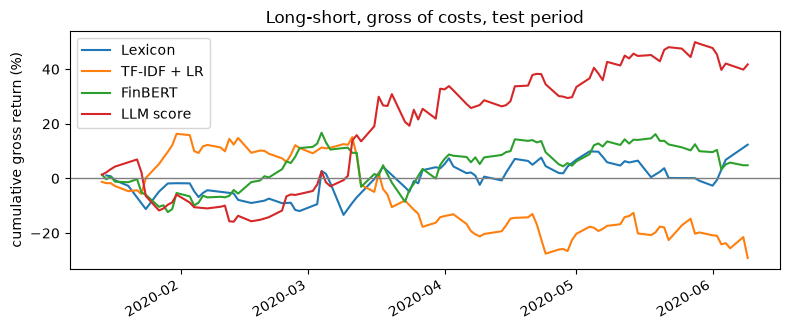

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, g in daily_test.items():
    (g['gross'].cumsum() * 100).plot(ax=ax, label=name)
ax.axhline(0, color='grey', lw=1); ax.set_ylabel('cumulative gross return (%)'); ax.set_xlabel('')
ax.set_title('Long-short, gross of costs, test period'); ax.legend(); plt.tight_layout(); plt.show()

**Full sample for the untrained signals.** The lexicon and FinBERT are never trained on returns, so they can be evaluated on
all 30,000 rows (636 days, including calm markets). That gives much more statistical power than the 107 test days.

In [7]:
res_full, daily_full = run_backtest(ds, {'Lexicon': 'lexicon', 'FinBERT': 'finbert'})
display(res_full.astype(float).round(2))
print(f'days: {ds["entry_date"].nunique()} (all rows)')

,days,names/leg,gross (bps),CI low,CI high,t,net @10bp (bps),Sharpe gross,Sharpe net,hit,break-even (bps/trade)
signal,,,,,,,,,,,
Lexicon,491.0,4.70,-0.41,-16.88,15.79,-0.05,-40.41,-0.04,-3.54,0.50,-0.1
FinBERT,615.0,6.29,-5.19,-16.25,5.39,-0.93,-45.19,-0.59,-5.16,0.51,-1.3


days: 636 (all rows)


## 6. Cost sensitivity

The net mean is $\bar g - 4c$. Below, the net mean in basis points for different per-trade costs, next to the gross mean.
Zero cost is a theoretical upper bound; 5-10 bps per trade is a plausible range for liquid large caps with closing-price
execution, but this is an assumption, not something measured.

In [8]:
rows = []
for label, daily in [('test period', daily_test), ('full sample', daily_full)]:
    for name, g in daily.items():
        row = {'period': label, 'signal': name, 'gross (bps)': g['gross'].mean() * 1e4}
        for c in [0, 2, 5, 10]:
            row[f'net @{c}bp'] = net_of_costs(g['gross'], c).mean() * 1e4
        rows.append(row)
display(pd.DataFrame(rows).set_index(['period', 'signal']).astype(float).round(2))

gross (bps)  net @0bp  net @2bp  net @5bp  net @10bp
period      signal                                                           
test period Lexicon            16.05     16.05      8.05     -3.95     -23.95
            TF-IDF + LR       -28.55    -28.55    -36.55    -48.55     -68.55
            FinBERT             4.73      4.73     -3.27    -15.27     -35.27
            LLM score          43.48     43.48     35.48     23.48       3.48
full sample Lexicon            -0.41     -0.41     -8.41    -20.41     -40.41
            FinBERT            -5.19     -5.19    -13.19    -25.19     -45.19

## 7. Caveats that apply to every number above

- **Selection of the universe.** The 100 most-covered tickers that still have prices today (survivorship bias; mostly large caps, but 15 of the 100 tickers are ETFs).
- **Entry rule.** Most news is date-only, so we trade from the *next* close. This tests drift, not the immediate reaction.
- **Costs are a worst-case assumption** (full daily turnover, flat 10 bps); borrow fees and market impact are not modelled.
- **Few test days.** 107 days, in a period that includes the March 2020 crash; intervals are wide.
- **Several signals compared.** Looking at many signals makes a lucky one likely; no multiple-testing correction is applied.
- **Closing-price fills.** We assume we can trade at the close that the return is measured from.

## Takeaways (numbers copied from the outputs above)

**Setup.** 30,000 headlines became 18,126 ticker-days. The LLM scored a random 3,000 of the 7,542 test headlines (40%), so every
test-period row of the results table uses those 3,000 rows for all four signals. That leaves only about 4-5 stocks per leg per day,
so each daily spread is noisy. Costs: 10 bps per trade, full daily turnover (40 bps per day).

**The machinery works.** On the real test cross-section, a pure-noise signal earned -24.9 bps per day gross with an interval of
[-70.5, +15.9] (contains 0), a weak planted signal earned +168 bps [+121, +221], and the oracle earned +887 bps. Net was
exactly gross minus 40 bps on every day. So a real signal would have been detected, and noise did not look profitable.

**Results (gross mean per day, 95% day-bootstrap interval, test period, the same 3,000 rows)**

| Signal | Days | Gross, bps | 95% interval | t | Net @ 10 bps |
|---|---|---|---|---|---|
| Lexicon | 77 | +16.1 | [-61.3, +92.3] | 0.41 | -24.0 |
| TF-IDF + logistic regression | 102 | -28.6 | [-87.9, +30.0] | -0.94 | -68.6 |
| FinBERT | 102 | +4.7 | [-50.6, +56.4] | 0.17 | -35.3 |
| **LLM score (gpt-oss-20b, zero-shot)** | 96 | **+43.5** | **[-31.3, +115.7]** | **1.16** | **+3.5** |

Notebook 03 gives the matching rank-correlation view on the same rows: mean daily IC of +0.023 for the LLM [-0.026, +0.076]
against +0.014 for FinBERT, and a direction accuracy of 48.95% [46.2, 51.9] for the LLM (the majority-class rate on the whole
dataset was 50.8%).

**Reading it honestly**

1. **No signal is distinguishable from zero, the LLM included.** Every interval contains 0. The LLM has the largest point estimate
   (+43 bps gross, 56% of days positive) but its interval runs from -31 to +116 bps, and its mean daily IC is as close to 0 as
   FinBERT's.
2. **The size of the LLM's number is not unusual for this sample.** Notebook 04 first ran the lexicon on all 7,542 test rows and got
   +56 bps [-4, +117]. On the 3,000-row subset the same lexicon gives +16 bps. The signal did not change, the sample did. A swing
   of 40 bps from the choice of rows alone is the same size as the LLM's whole advantage.
3. **After costs the LLM is at about break-even, not profitable.** +3.5 bps net at 10 bps per trade (break-even 10.9 bps per
   trade, Sharpe 0.15 net). It is positive at 2 and 5 bps only if you trust the gross point estimate, which the interval does not
   support. Every other signal is negative at 5 and 10 bps.
4. **Sharpe ratios are descriptive only.** With about 100 days and wide intervals, a gross Sharpe of 1.9 carries no weight.
5. **Multiple looks.** Four signals and two periods were examined. One of them showing t = 1.2 is what chance produces.

**What this means for the research question.** On this sample we cannot say that LLM-extracted sentiment predicts next-day abnormal
returns better than a lexicon or FinBERT, and we also cannot say it does not: an interval of [-31, +116] bps is compatible with a
modest edge and with a loss. The sample (106 test days, 3,000 headlines, one model, one prompt, a crash period) is too small to
separate an edge smaller than about 75 bps per day (the half-width of the LLM's interval) from zero. A null here is a statement about statistical power as much as about the model.

**Limitations that apply to all of the above:** survivorship-biased universe (mostly large caps, plus 15 ETFs), next-day entry because most news is
date-only (so this tests drift, not the immediate reaction), worst-case flat costs with no borrow fees, very few test days,
closing-price fills, and the model may remember 2020 (see notebook 05).